In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [49]:
sales_data = pd.read_csv("ecommerce_sales.csv")
# sales_data.head()

In [4]:
total_revenue = sales_data['revenue'].sum()
print(f"Total Revenue: Rs. {total_revenue:,.2f}")

Total Revenue: Rs. 5,109,775.74


The total revenue represents the sum of revenue generated from all orders in the dataset.

In [5]:
total_orders = sales_data['order_id'].nunique()
print(f"Total Orders: {total_orders}")

Total Orders: 5000


In [6]:
unique_customers = sales_data['customer_id'].nunique()
print(f"There are {unique_customers} unique customers.")

There are 989 unique customers.


In [7]:
average_revenue_per_order = total_revenue/total_orders


In [8]:
total_quantity_sold = sales_data['quantity'].sum()


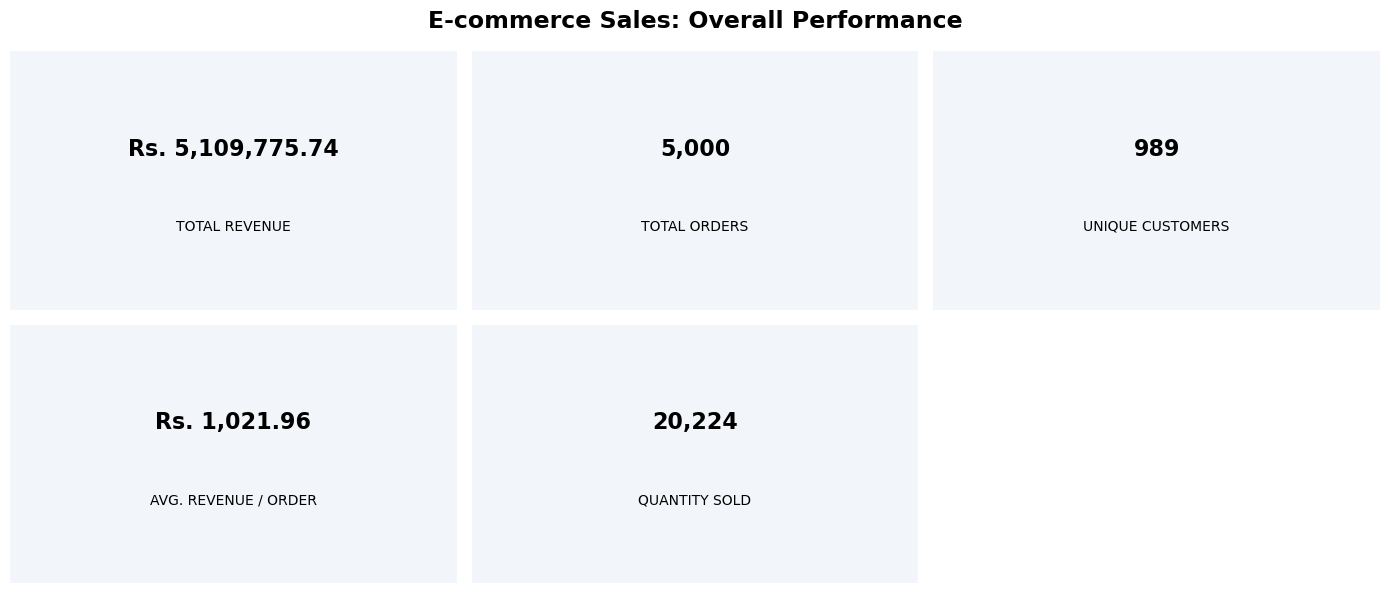

In [9]:


# Create KPI values
kpis = [
    ("TOTAL REVENUE", f"Rs. {total_revenue:,.2f}"),
    ("TOTAL ORDERS", f"{total_orders:,}"),
    ("UNIQUE CUSTOMERS", f"{unique_customers:,}"),
    ("AVG. REVENUE / ORDER", f"Rs. {average_revenue_per_order:,.2f}"),
    ("QUANTITY SOLD", f"{total_quantity_sold:,}")
]

fig,axes = plt.subplots(2,3,figsize=(14,6))
axes = axes.flatten()

for i, (title, value) in enumerate(kpis):
    axes[i].set_facecolor("#F2F5F9")
    axes[i].text(
        0.5, 0.62, value,
        ha="center", va="center",
        fontsize=16, fontweight="bold",
        transform=axes[i].transAxes
    )
    axes[i].text(
        0.5, 0.32, title,
        ha="center", va="center",
        fontsize=10,
        transform=axes[i].transAxes
    )

    axes[i].set_xticks([])
    axes[i].set_yticks([])

    for spine in axes[i].spines.values():
        spine.set_visible(False)

# Hide the unused sixth card
axes[5].axis("off")

fig.suptitle(
    "E-commerce Sales: Overall Performance",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


The summary of KPIs gives a brief description of the performance of the e-commerce business. The total revenue shows the income generated; total orders and unique customers represents sales activity, average revenue per order shows the income per transaction, while the total quantity sold shows the number of products sold.

### OVERALL SALES ANALYSIS

In [10]:
revenue_by_category = sales_data.groupby('product_category')['revenue'].sum().round(2).sort_values(ascending=False)
revenue_by_category

product_category
Electronics    1829899.22
Clothing       1531931.72
Home            982083.92
Beauty          765860.88
Name: revenue, dtype: float64

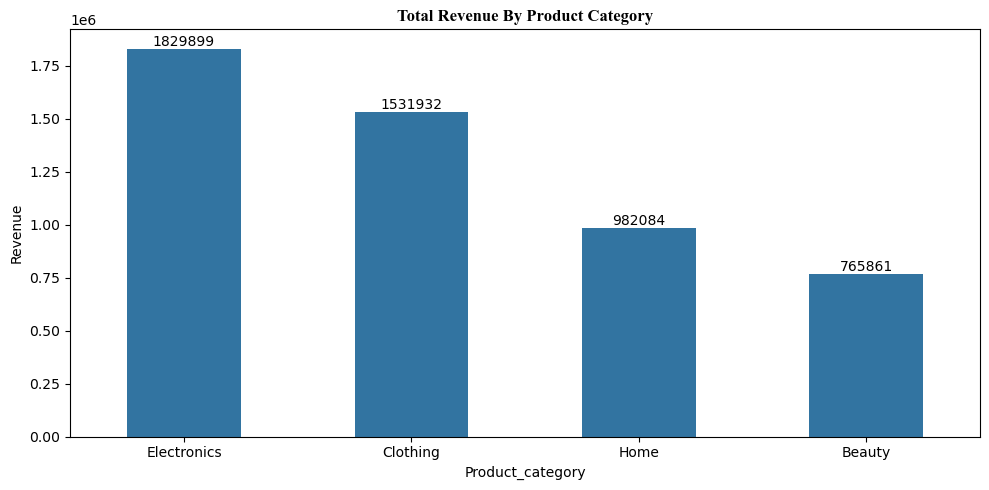

In [11]:
plt.figure(figsize=(10,5))
ax=sns.barplot(x=revenue_by_category.index,y=revenue_by_category.values,width=0.5)
for container in ax.containers:
    ax.bar_label(container,fmt='%.0f')
plt.title('Total Revenue By Product Category',fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel('Product_category')
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

Electronics product generated the highest revenue, followed by clothing. Home and Beauty contributed less to revenue compared to the other two categories, with Beauty having the lowest sales revenue.This shows that Electronics is performing well, while the business could explore ways to improve sales in the Beauty category.

In [56]:
sales_data.order_date = pd.to_datetime(sales_data.order_date )

In [57]:
monthly_revenue = (
    sales_data.groupby(sales_data['order_date'].dt.month)['revenue']
    .sum()
    .sort_index()
)
# monthly_revenue

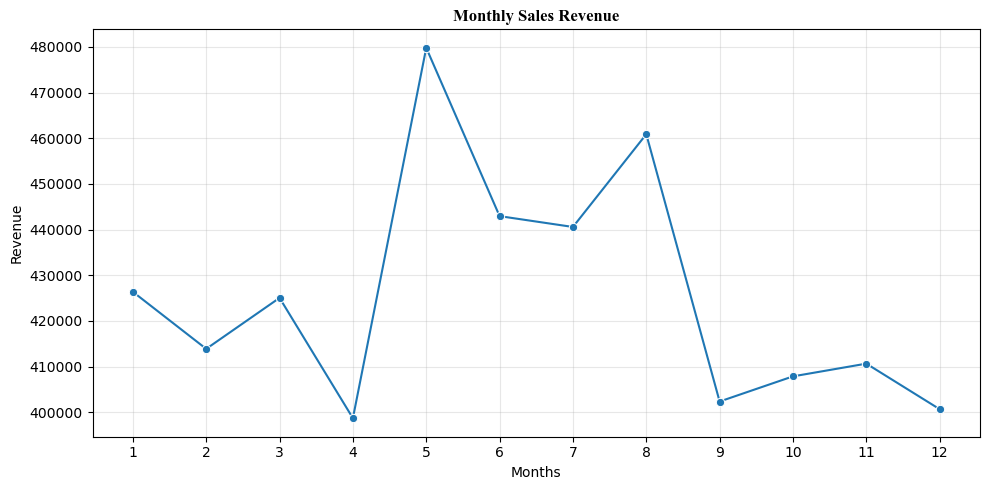

In [58]:
plt.figure(figsize=(10,5))
sns.lineplot(monthly_revenue,marker='o')
plt.title("Monthly Sales Revenue",fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel('Months')
plt.ylabel('Revenue')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

May generated the highest revenue, followed by August, while April had the lowest revenue. This shows that sales revenue varied from month to month. The business can look at what made May more successful and use those findings to improve sales during months with lower revenue.

In [60]:
Yearly_sales_revenue = sales_data.groupby(sales_data['order_date'].dt.year)['revenue'].sum().sort_values(ascending=False)
# Yearly_sales_revenue

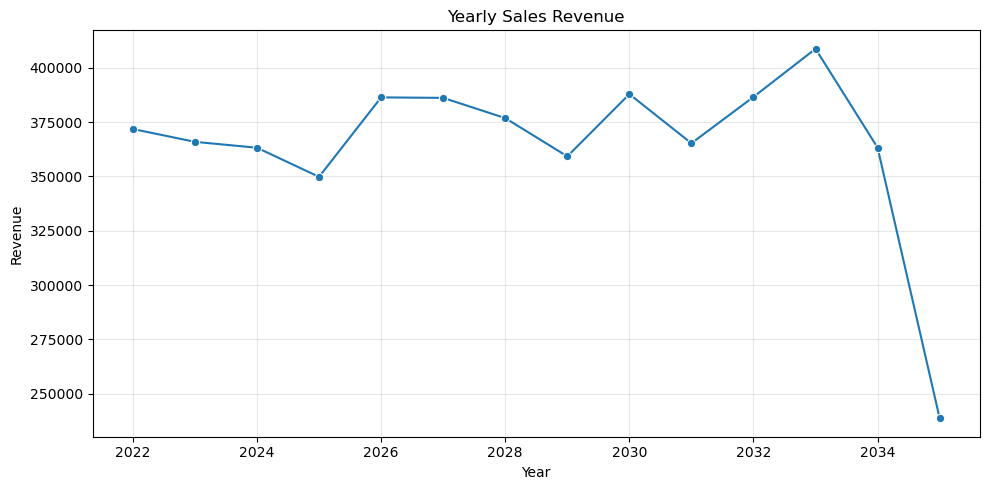

In [61]:
plt.figure(figsize=(10,5))
sns.lineplot(Yearly_sales_revenue,marker='o')
plt.title('Yearly Sales Revenue')
plt.xlabel('Year')
plt.ylabel('Revenue')
plt.tight_layout()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Yearly sales revenue went up and down over the years instead of showing steady growth. Revenue was highest in 2033 and lowest in 2035. The drop in revenue in 2035 suggests that the business should look into possible reasons for the decline and find ways to improve sales.

In [17]:
monthly_orders = (
    sales_data.groupby(sales_data['order_date'].dt.month)['order_id']
    .nunique()
    .sort_index()
)
# monthly_orders

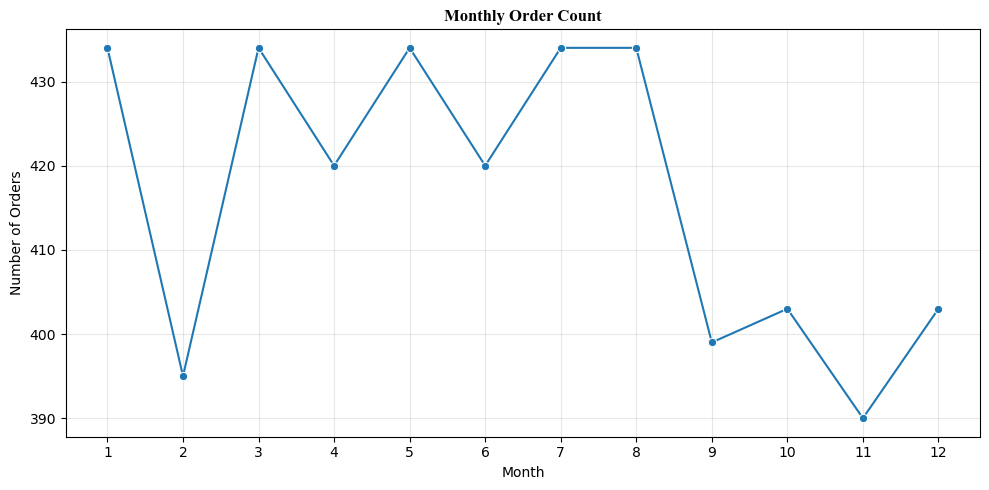

In [18]:
plt.figure(figsize=(10, 5))
sns.lineplot(x=monthly_orders.index, y=monthly_orders.values, marker='o')
plt.title('Monthly Order Count',fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


January, March, May, July, and August had the highest number of orders, with 434 orders each. November had the fewest orders, with 390. Overall, the number of orders was fairly stable throughout the year, although November had slightly lower sales activity than the other months.

### PRODUCT CATEGORY ANALYSIS

#### Which product category generates highest revenue?

In [62]:
revenue_by_category = sales_data.groupby('product_category')['revenue'].sum().sort_values(ascending=False)
# revenue_by_category

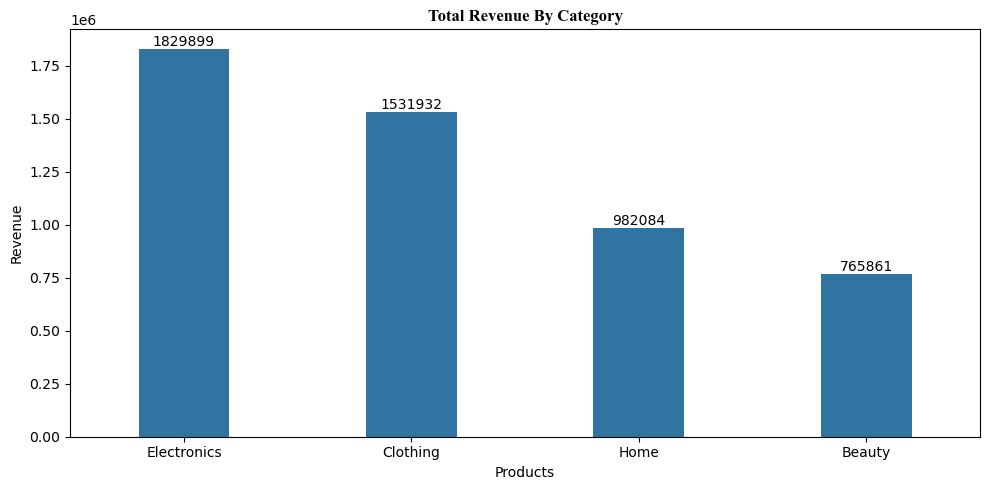

In [21]:
plt.figure(figsize=(10,5))
ax=sns.barplot(x=revenue_by_category.index,y=revenue_by_category.values,width=0.4)
for container in ax.containers:
    ax.bar_label(container,fmt='%.0f')
plt.title('Total Revenue By Category',fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel('Products')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()

Electronics product generated the highest revenue, followed by clothing. Home and Beauty contributed less to revenue compared to the other two categories, with Beauty having the lowest sales revenue.This shows that Electronics is performing well, while the business could explore ways to improve sales in the Beauty category.

#### Which category sells the most quantity?

In [22]:
quantity_by_category = sales_data.groupby('product_category')['quantity'].sum().sort_values(ascending=False)
# quantity_by_category

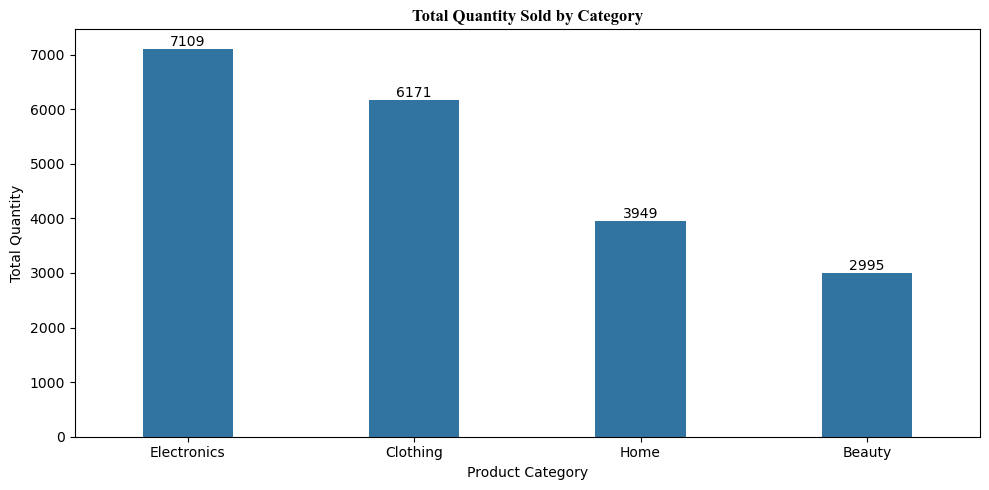

In [23]:
plt.figure(figsize=(10,5))
ax=sns.barplot(x=quantity_by_category.index,y=quantity_by_category.values,width=0.4,color='steelblue',edgecolor='black')
for container in ax.containers:
    ax.bar_label(container,fmt='%.0f')
plt.title("Total Quantity Sold by Category",fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel("Product Category")
plt.ylabel("Total Quantity")
plt.tight_layout()
plt.show()

Electronics had the highest quantity sold, with 7,109 units, followed by Clothing with 6,171 units. Home and Beauty had lower sales quantities, with 3,949 and 2,995 units, respectively. Overall, Electronics and Clothing were the most popular categories in terms of quantity sold, while Beauty had the lowest sales.

#### Which category has the highest average customer rating?

In [63]:
rating_by_category=sales_data.groupby('product_category')['customer_rating'].mean()
# rating_by_category

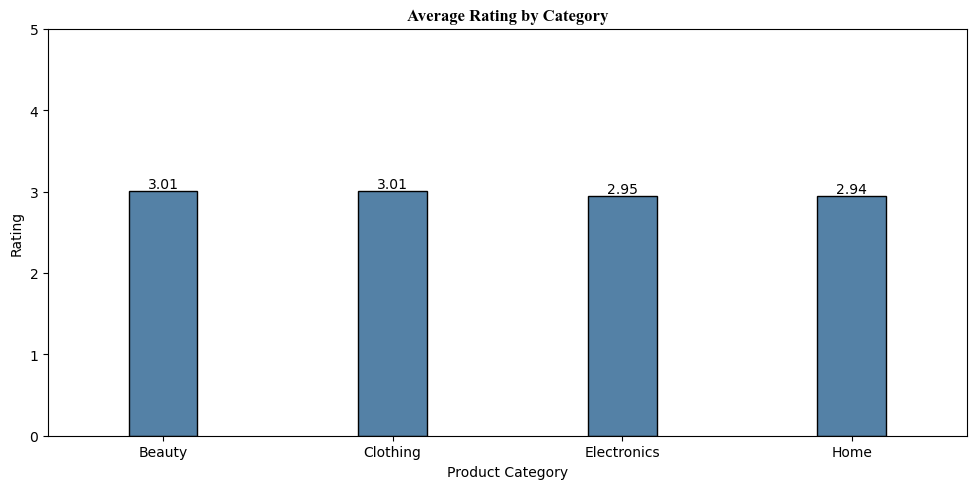

In [76]:
plt.figure(figsize=(10,5))
ax=sns.barplot(x=rating_by_category.index,y=rating_by_category.values,width=0.3,color='steelblue',edgecolor='black')
for container in ax.containers:
    ax.bar_label(container,fmt='%.2f')
plt.title('Average Rating by Category',fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel('Product Category')
plt.ylabel('Rating')
plt.tight_layout()
plt.ylim((0,5))
plt.show()

Beauty had the highest average customer rating of 3.01, closely followed by Clothing at 3.01. Electronics received an average rating of 2.95, while Home had the lowest rating of 2.94. Overall, customer ratings were very similar across all categories, staying around 3 out of 5, which suggests there is room to improve customer satisfaction across the product categories.

#### Conclusion
Electronics performed best in both revenue and quantity sold, followed by Clothing. Beauty had the lowest sales but the highest average customer rating. Overall, the business should focus on its top-performing categories while improving sales and customer satisfaction across all categories.

### Regional Sales Analysis

#### Which region generates the highest revenue?

In [26]:
region_wise_revenue = sales_data.groupby('region')['revenue'].sum().sort_values(ascending=False)
# print(f"Revenue By Region \n\n{region_wise_revenue}\n")

region_wise_orders = sales_data.groupby('region')['order_id'].nunique()
# print(f"Order count By Region \n\n {region_wise_orders}\n")

region_wise_rating = sales_data.groupby('region')['customer_rating'].mean().round(2)
# print(f"Rating By Region \n\n{region_wise_rating}\n")

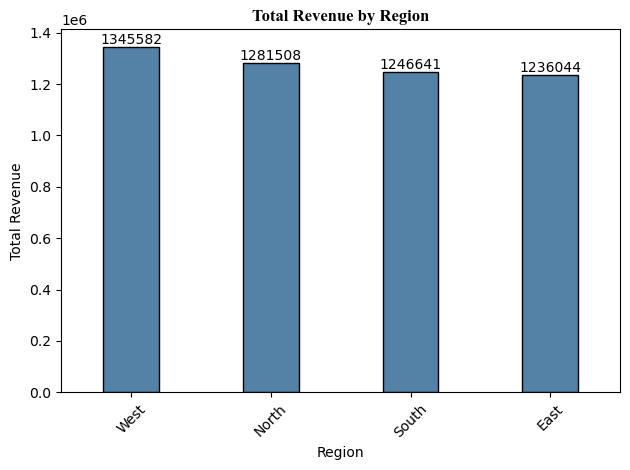

In [75]:
ax=sns.barplot(
    x=region_wise_revenue.index,
    y=region_wise_revenue.values,
    width=0.4,color='steelblue',edgecolor='black'
)
for container in ax.containers:
    ax.bar_label(container,fmt='%.0f')
plt.title('Total Revenue by Region',fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel('Region')
plt.ylabel('Total Revenue')
plt.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

The West region generated the highest revenue of 1,345,582.16, followed by the North region. The East region recorded the lowest revenue at 1,236,044.23. Overall, revenue was relatively balanced across all four regions, but the West region contributed the most to total sales.

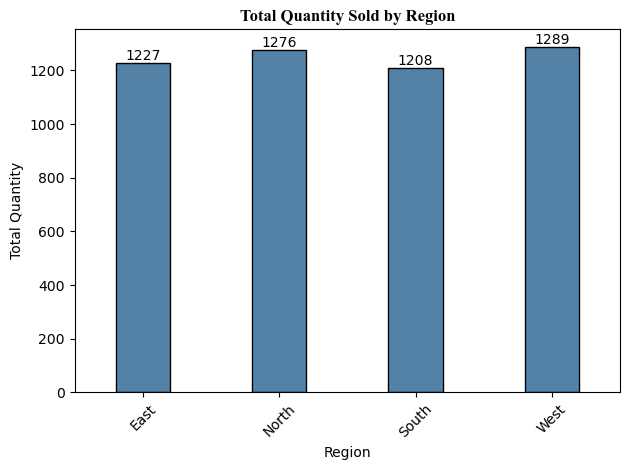

In [74]:
ax=sns.barplot(
    x=region_wise_orders.index,
    y=region_wise_orders.values,
    width=0.4,color='steelblue',edgecolor='black'
)
for container in ax.containers:
    ax.bar_label(container,fmt='%.0f')
plt.title('Total Quantity Sold by Region',fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel('Region')
plt.ylabel('Total Quantity')
plt.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


The West region sold the highest quantity of products, followed closely by the North region. The South region recorded the lowest quantity sold, while the East region performed slightly better. This indicates that the West region performed strongly in terms of both revenue and sales volume.

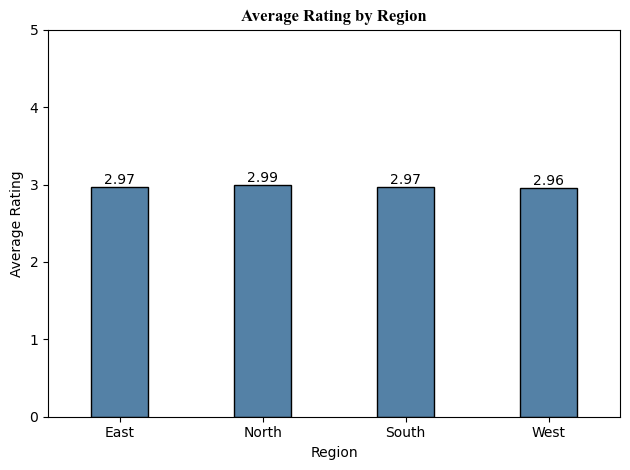

In [73]:
ax= sns.barplot(
    x=region_wise_rating.index,
    y=region_wise_rating.values,
    width=0.4,color='steelblue',edgecolor='black'
)

for container in ax.containers:
    ax.bar_label(container,fmt='%.2f')
plt.title('Average Rating by Region',fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel('Region')
plt.ylabel('Average Rating')
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

The North region received the highest average customer rating of approximately 2.99, while the West region had the lowest at approximately 2.96. The differences are very small, and all regions have ratings close to 3 out of 5. This suggests that customer feedback is fairly consistent across regions, but customer satisfaction could be improved.

### Conclusion
The West region was the strongest performer in terms of revenue and quantity sold, while the North region achieved the highest customer rating. Although sales performance was relatively balanced across all regions, average customer ratings remained around 3 out of 5. The business should focus on maintaining strong sales in the West while improving customer satisfaction across all regions through better product quality, delivery services, and customer support.

### Customer Analysis

In [30]:
revenue_by_customers = sales_data.groupby('customer_id')['revenue'].sum().round(2).sort_values(ascending=False).head(10)
# print(revenue_by_customers)

orders_per_customers = sales_data.groupby('customer_id')['order_id'].nunique()
# print(orders_per_customers)

revenue_per_orders=sales_data.groupby('order_id')['revenue'].sum()
# revenue_by_orders

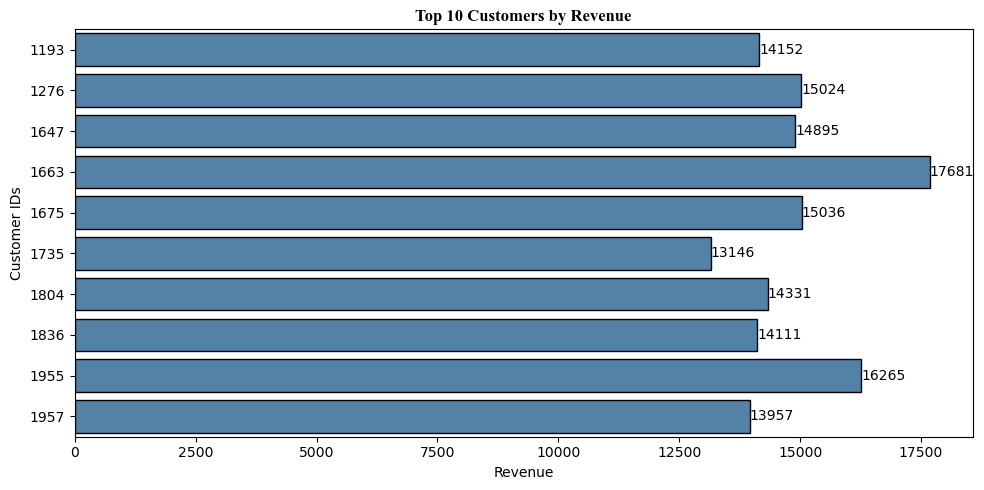

In [71]:
plt.figure(figsize=(10,5))
ax=sns.barplot(x=revenue_by_customers.values,
            y=revenue_by_customers.index,
            orient='h',color='steelblue',edgecolor='black')
for container in ax.containers:
    ax.bar_label(container,fmt='%.0f')
plt.title('Top 10 Customers by Revenue',fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.ylabel('Customer IDs')
plt.xlabel('Revenue')
plt.tight_layout()
plt.show()

The chart shows which customers bring in the most revenue for the business. These customers are valuable because they contribute a good amount to overall sales. The business should focus on keeping these customers satisfied and encouraging them to continue shopping.

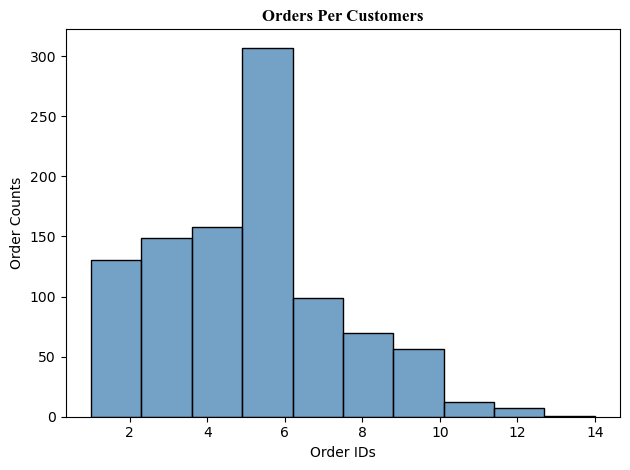

In [72]:
sns.histplot(orders_per_customers,kde=False,bins=10,color='steelblue',edgecolor='black')
plt.title('Orders Per Customers',fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel('Order IDs')
plt.ylabel('Order Counts')
plt.tight_layout()
plt.show()

The chart helps us understand how often customers purchase from the business. Some customers order more frequently than others, which shows that purchasing habits vary. The business could encourage customers who order less often to return and make more purchases.

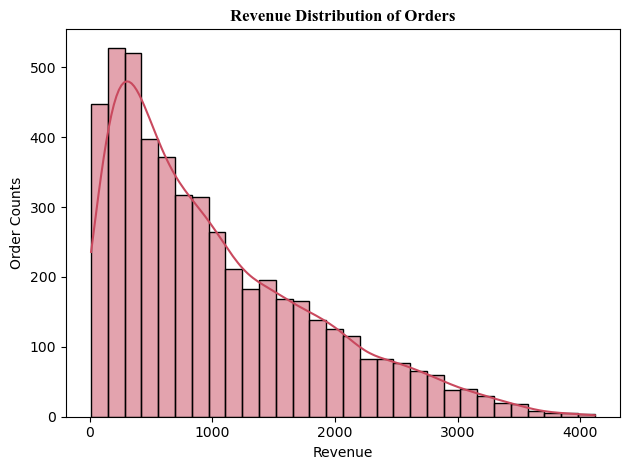

In [33]:
sns.histplot(revenue_per_orders, bins=30, kde=True,color='#C9495E')
plt.title('Revenue Distribution of Orders',fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel('Revenue')
plt.ylabel('Order Counts')
plt.tight_layout()
plt.show()

The chart shows that most orders generate relatively low revenue, while only a few orders generate much higher revenue. This means high-value orders are less common. The business could encourage customers to purchase additional or related products to increase the amount spent per order.

#### Conclusion
Customer analysis shows that the business has customers with different purchasing patterns. Most customers place around 5–6 orders, and most individual orders generate relatively low revenue. A small number of orders contribute higher amounts, while the top customers provide valuable revenue to the business. The company could focus on customer retention, encouraging repeat purchases, and increasing the value of smaller orders to improve overall sales performance.

### Payment Method Analysis

### Order count by payment method

In [66]:
order_by_payment = sales_data.groupby('payment_method')['order_id'].nunique().sort_values(ascending=False)
# order_by_payment

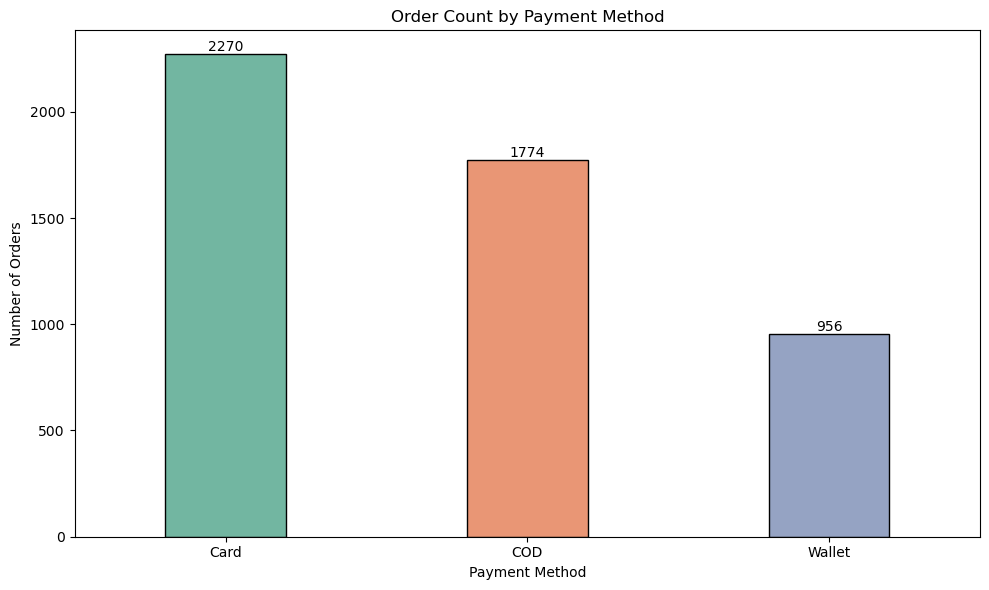

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=order_by_payment.index,
    y=order_by_payment.values,
    hue=order_by_payment.index,
    palette='Set2',
    legend=False,
    width=0.4,
    edgecolor='black'
)

# Display order counts above the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.title('Order Count by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

Card is the most popular payment method, followed by COD, while Wallet has the fewest orders. This shows that customers prefer card payments, although cash on delivery remains a common choice.

### Total revenue by payment method

In [36]:
total_revenue_by_payment = sales_data.groupby('payment_method')['revenue'].sum()
# total_revenue_by_payment

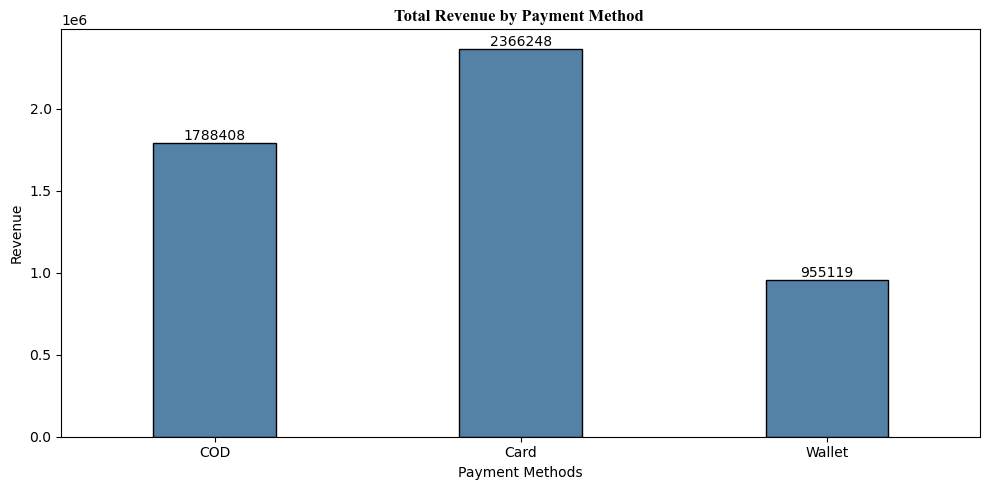

In [69]:
plt.figure(figsize=(10,5))
ax=(sns.barplot(x=total_revenue_by_payment.index,y=total_revenue_by_payment.values,width=0.4,color='steelblue',edgecolor='black'))
for container in ax.containers:
    ax.bar_label(container,fmt='%.0f')
plt.title("Total Revenue by Payment Method ",fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel("Payment Methods")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

Card payments generate the highest revenue (2,366,248), followed by COD (1,788,408). Wallet payments generate the lowest revenue (955,119), indicating that card payments contribute the most to overall sales.

### Average order revenue by payment method

In [38]:
avg_revenue_by_payment = sales_data.groupby('payment_method')['revenue'].mean().round(2)
# avg_revenue_by_payment

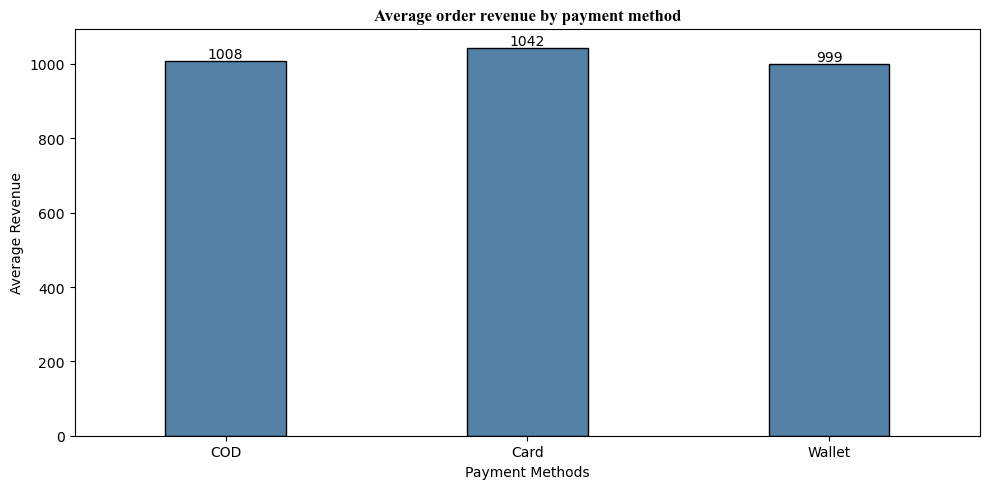

In [68]:
plt.figure(figsize=(10,5))
ax=sns.barplot(x=avg_revenue_by_payment.index,y=avg_revenue_by_payment.values,width=0.4,color='steelblue',edgecolor='black')
for container in ax.containers:
    ax.bar_label(container,fmt='%.0f')
plt.title("Average order revenue by payment method",fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel("Payment Methods")
plt.ylabel("Average Revenue")
plt.tight_layout()
plt.show()

Card payments have the highest average order revenue at 1,042, followed by COD at 1,008 and Wallet at 999. However, the differences are small, suggesting that average order revenue is fairly similar across all three payment methods.

#### Conclusion
Card is the most preferred payment method and generates the highest total revenue and average revenue per order. COD remains the second most popular option, while Wallet has the lowest order count and total revenue. Overall, the business should continue supporting all three payment methods to meet different customer preferences.

### Discounts and Revenue

#### Discount vs. revenue

<Axes: xlabel='discount', ylabel='revenue'>

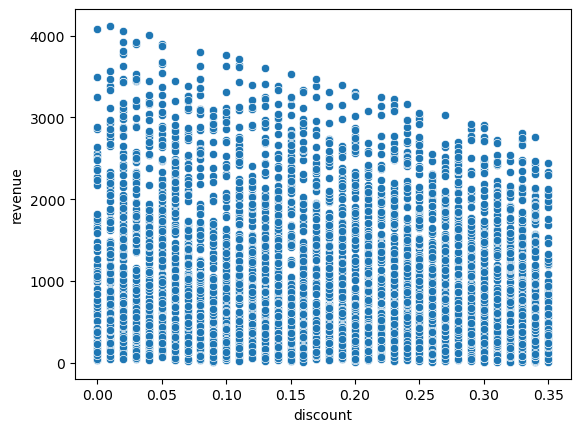

In [40]:
sns.scatterplot(sales_data,x='discount',y='revenue')

The chart shows that orders with lower discounts sometimes generate higher revenue, while higher discounts generally have lower maximum revenue. However, revenue varies at all discount levels, suggesting that factors such as product price and quantity purchased also play an important role.

#### Discount distribution

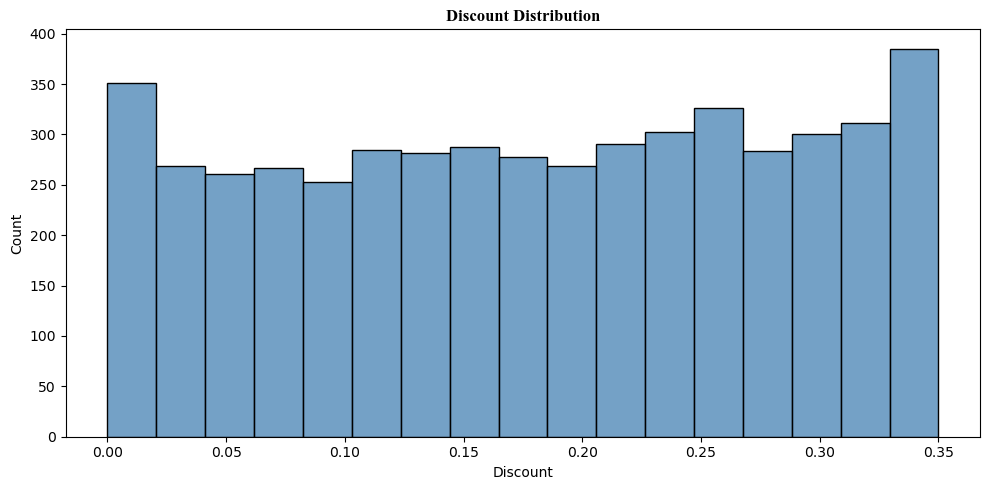

In [41]:
plt.figure(figsize=(10, 5))
sns.histplot(sales_data['discount'], bins=17, color='steelblue', edgecolor='black')

plt.title("Discount Distribution",
          fontdict={'fontweight': 'bold', 'fontsize': 12, 'fontfamily': 'Times New Roman'})
plt.xlabel("Discount")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Discounts are spread across the 0%–35% range, with higher frequencies near 0% and 33%–35%. This suggests the business uses a mix of low and high discounts in its sales strategy.

#### Conclusion
The charts show that discounts range from 0% to 35%, but higher discounts do not necessarily result in higher revenue. Revenue generally tends to be higher at lower discount levels, suggesting that offering excessive discounts may not always be beneficial. Therefore, the business should use discounts wisely to attract customers while maintaining revenue and profitability.

### Delivery and Customer Satisfaction

#### Delivery days vs. customer rating

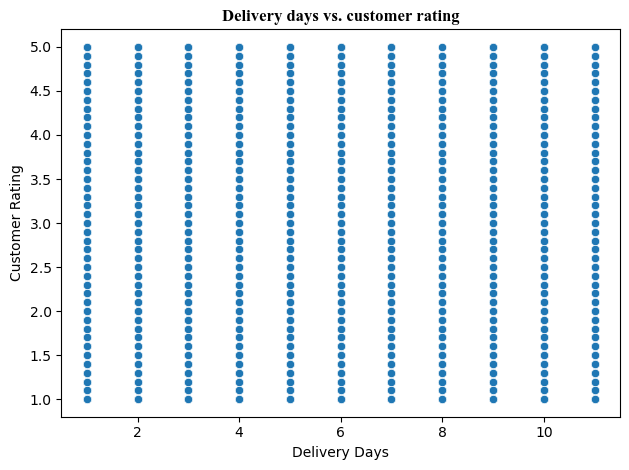

In [42]:
sns.scatterplot(sales_data,x='delivery_days',y='customer_rating')
plt.title("Delivery days vs. customer rating",fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel("Delivery Days")
plt.ylabel("Customer Rating")
plt.tight_layout()
plt.show()

Customer ratings vary widely at each delivery duration, with both high and low ratings appearing across all delivery times. This suggests that there is no clear relationship between delivery days and individual customer ratings.

#### Average rating by delivery duration

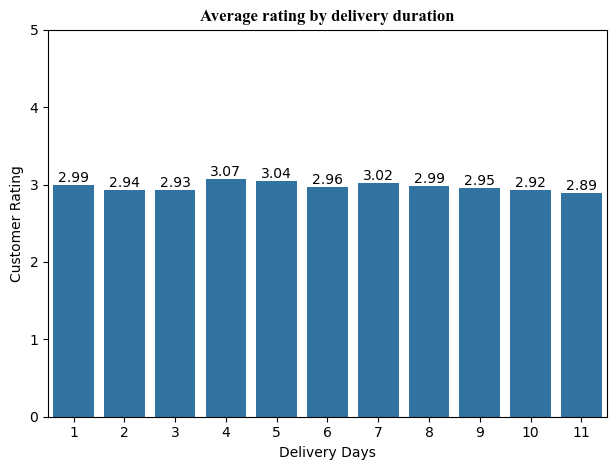

In [43]:
rating_by_delivery=sales_data.groupby('delivery_days')['customer_rating'].mean()
ax=sns.barplot(x=rating_by_delivery.index,y=rating_by_delivery.values)
for container in ax.containers:
    ax.bar_label(container,fmt='%.2f')
plt.title("Average rating by delivery duration",fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel("Delivery Days")
plt.ylabel("Customer Rating")
plt.tight_layout()
plt.ylim((0,5))
plt.show()

The average customer rating remains close to 3 out of 5 across all delivery durations. The small differences between delivery days suggest that average ratings are fairly consistent regardless of how long delivery takes.

#### Customer rating distribution

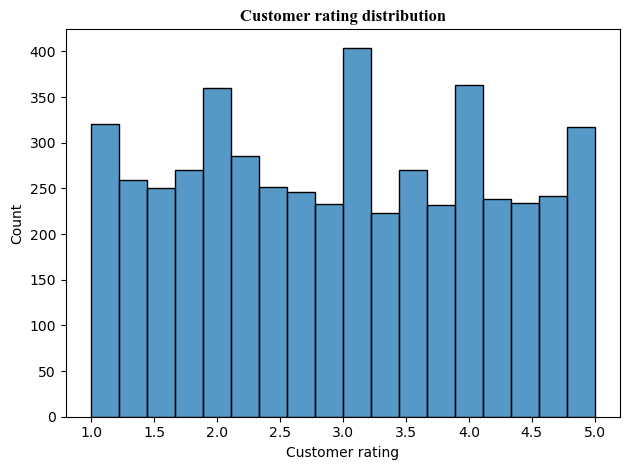

In [44]:
sns.histplot(sales_data.customer_rating)
plt.title("Customer rating distribution",fontdict={'fontweight':'bold','fontsize':'12','fontfamily':'Times New Roman'})
plt.xlabel("Customer rating")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Customer ratings are spread across the range of 1 to 5, showing different levels of customer satisfaction. Ratings around 3 and 4 are relatively common, but lower ratings are also noticeable. This suggests that while many customers are reasonably satisfied, there is still room to improve the customer experience.

#### Conclusion
Overall, customer ratings are distributed across the full range, and the average rating is around 3 out of 5. Delivery duration does not appear to have a strong relationship with customer satisfaction, suggesting that other factors, such as product quality, service, and customer experience, may also influence ratings.

In [45]:
# %cd ..

In [46]:
# !git add ecommerce_sales_analysis/ecommerce_sales_visualization.ipynb

In [47]:
# !git commit -m "Add Discount and Revenue analysis insights"

In [48]:
# !git push origin main